## How to run this notebook

**What it does.** Exploratory data analysis (task A2-09) of the Bank Account Fraud (BAF) Base data: class balance, fraud rate by month, missing codes, fraud rate by category, how well each feature separates fraud from legitimate applications (KS distance, Cramér's V, recall at 5% false-positive rate), feature redundancy, age groups and feature drift (PSI). The results feed the report's data-analysis section and its EDA figures and tables. The stored cell outputs and figures are kept in this file.

**Data used.** Development months 0–5 only (794,989 applications, 8,151 frauds). The one exception is the descriptive month-by-month fraud-rate table and chart (Figures 1–2 in the notebook), which also show months 6–7 for context. Nothing is fitted or selected on months 6–7.

**Where to put the data.** The raw file is not in Git. Download `Base.csv` (or the Kaggle `Base.csv.zip`) from <https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022> and place it in `experiment_suite/dataset/baf/`. The setup cell also accepts `notebooks/data/` or the repository root, and reads the zip directly.

**To run.** Use the repository's conda environment (`conda activate fraudsuite`, see the README) with Jupyter installed (`pip install jupyterlab` if missing). Open this file and choose Run All (about 2 minutes when it was checked). Paths are relative, so it works from `notebooks/` or from the repository root. The helper code is in `notebooks/a2_analysis/eda.py`.

**Files it writes** (all under `notebooks/a2_outputs/`, safe to delete and re-create):
- `figures/fig01_…` to `fig11_…` (`.png`): class balance, fraud rate by month, missing codes, categories, binary flags, numeric distributions, Spearman correlation, feature association, age, ordinal features, drift.
- `tables/eda_*.csv`: the result tables (monthly rates, category levels, missing patterns, numeric separation, association, single-feature recall, age groups, drift, …).
- `chart_data.json`: the values behind the figures.

# 02 – Exploratory Data Analysis (EDA) of BAF Base

**COS30049 Assignment 2 · Group COS30049.2_1 · Task A2-09**
Owner: Thông · Reviewer: Kha

**Goal.** Understand the Bank Account Fraud (BAF) Base dataset before modelling:
- how rare fraud is;
- how fraud and the features change over time;
- which features carry signal;
- how missing values behave;
- which features are redundant.

The findings feed:
- preprocessing (A2-07);
- imbalance handling (A2-08);
- model choice (A2-11, A2-12, A2-13);
- the threshold (A2-14);
- the fairness check (A2-16).

**Done when** (tracker): at least 6 labelled matplotlib/seaborn figures, legible at A4, saved to `notebooks/a2_outputs/figures/`.

**Leakage rule.**
- Section 3 (Figures 1–2) describes all eight months. It shows the test months for context only: the temporal split and the recall-at-5%-FPR metric come from the BAF benchmark protocol, not from these figures.
- Everything else (Figures 3–11 and every table except `eda_monthly.csv`) uses **only the development months 0–5**, so the test months 6–7 stay unseen (risk R-A2-02).
- Values the model pipeline fits later (medians, scalers, rare-level lists) must be fitted on the training months inside the pipeline, not copied from these tables.

**Statistics used.**
- Fraud rates with 95% Wilson confidence intervals.
- A chi-square test of the monthly fraud rates.
- Kolmogorov–Smirnov (KS) distance between the fraud and legitimate distributions.
- Bias-corrected Cramér's V, with numeric features binned into deciles and "missing" as its own bin.
- Single-feature recall at 5% FPR (the benchmark metric).
- Spearman ρ for feature redundancy.
- Population Stability Index (PSI) for drift.

The data are synthetic (generated by a CTGAN model trained on real applications), so the patterns describe BAF, not real fraudsters directly.

Helper functions live in `a2_analysis/eda.py`; this notebook calls them in order and records the findings.

## 1. Setup

In [1]:
# Imports and project paths
import os
import sys
from pathlib import Path

import pandas as pd

# ROOT = the notebooks/ folder, found by walking up from the working directory until a2_analysis/eda.py appears,
# so the notebook runs from notebooks/, from the repository root or from any sub-folder.
_ROOTS = [p for base in [Path.cwd(), *Path.cwd().parents] for p in (base, base / "notebooks")]
ROOT = next((p for p in _ROOTS if (p / "a2_analysis" / "eda.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the repository (a2_analysis/eda.py not found).")
sys.path.insert(0, str(ROOT))
REPO = ROOT.parent

from a2_analysis import eda

# BAF Base, Kaggle v2 (Jesus et al., 2022; CC BY-NC-SA 4.0).
# Use the unzipped CSV if present, otherwise read the Kaggle zip directly. Raw data are never committed.
RAW = REPO / "experiment_suite" / "dataset" / "baf"
CANDIDATES = [RAW / "Base.csv", RAW / "Base.csv.zip", ROOT / "data" / "Base.csv", ROOT / "data" / "Base.csv.zip",
              REPO / "Base.csv", REPO / "Base.csv.zip"]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Base.csv not found. Download it from kaggle.com/datasets/sgpjesus/"
        "bank-account-fraud-dataset-neurips-2022 and put it in one of: "
        + ", ".join(os.path.relpath(p, REPO) for p in CANDIDATES))

# Everything this notebook writes goes under notebooks/a2_outputs/ (figures, tables, chart data).
OUT_DIR = ROOT / "a2_outputs"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

eda.set_style()

from IPython.display import Image, display

def show(path):
    """Display a saved figure inline at roughly its printed size."""
    display(Image(filename=str(path), width=720))

pd.set_option("display.float_format", "{:.4f}".format)
print("Reading", os.path.relpath(DATA_PATH, REPO))

Reading experiment_suite/dataset/baf/Base.csv.zip


## 2. Load and profile the data

In [2]:
# Load with downcast dtypes (1M rows, ~210 MB CSV)
df = eda.load_base(DATA_PATH)
print(f"All months: {len(df):,} rows x {df.shape[1]} columns, fraud rate {df[eda.TARGET].mean():.4%}")

# Development period only (months 0-5): used for everything from Section 4 on
dev = df[df["month"].isin(eda.DEV_MONTHS)].copy()
print(f"Development months 0-5: {len(dev):,} rows, {dev[eda.TARGET].sum():,} frauds, "
      f"fraud rate {dev[eda.TARGET].mean():.4%}, "
      f"class ratio {(dev[eda.TARGET] == 0).sum() / dev[eda.TARGET].sum():.1f} : 1")

All months: 1,000,000 rows x 32 columns, fraud rate 1.1029%
Development months 0-5: 794,989 rows, 8,151 frauds, fraud rate 1.0253%, class ratio 96.5 : 1


In [3]:
# Column profile on the development months: dtype, cardinality, missing-code share, range
profile = eda.profile_table(dev)
profile.to_csv(TABLE_DIR / "eda_profile_dev.csv", index=False)
profile

,column,dtype,n_unique,missing_share_pct,min,median,max
0,fraud_bool,int8,2,0.0000,0.0000,0.0000,1.0000
1,income,float32,9,0.0000,0.1000,0.6000,0.9000
2,name_email_similarity,float32,780333,0.0000,0.0000,0.4997,1.0000
3,prev_address_months_count,int16,370,71.5000,-1.0000,-1.0000,377.0000
4,current_address_months_count,int16,422,0.3800,-1.0000,53.0000,425.0000
5,customer_age,int8,9,0.0000,10.0000,30.0000,90.0000
6,days_since_request,float32,785471,0.0000,0.0000,0.0153,76.5815
7,intended_balcon_amount,float32,781971,73.7000,-15.5306,-0.8189,112.9569
8,payment_type,category,5,0.0000,NaN,NaN,NaN
9,zip_count_4w,int16,6300,0.0000,1.0000,1361.0000,6700.0000


In [4]:
# Data-quality checks (development months)
print("Duplicate rows:", dev.duplicated().sum())
print("True NaN cells:", int(dev.isna().sum().sum()))
print("Constant columns (no information):", [c for c in dev.columns if dev[c].nunique() == 1])
print("Negative velocity_6h values (not a missing code):", int((dev["velocity_6h"] < 0).sum()))
print("Negative credit_risk_score values (valid range starts at -170):", int((dev["credit_risk_score"] < 0).sum()))

Duplicate rows: 0
True NaN cells: 0


Constant columns (no information): ['device_fraud_count']
Negative velocity_6h values (not a missing code): 20
Negative credit_risk_score values (valid range starts at -170): 13435


## 3. Target and time (all months, descriptive only)

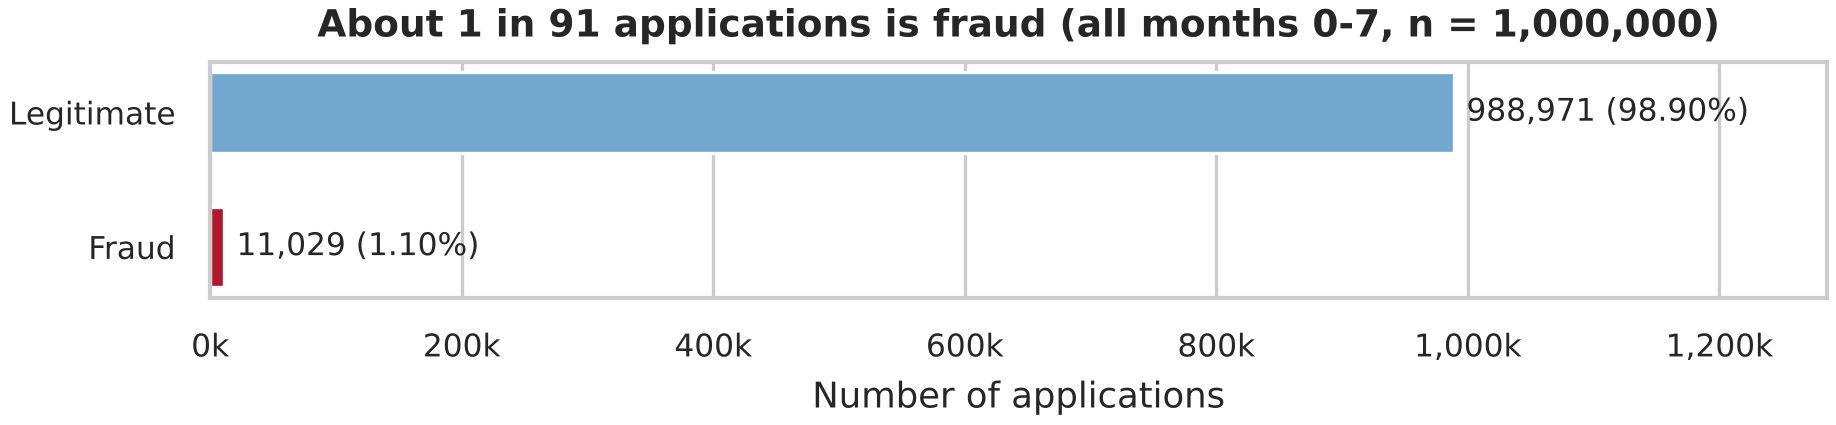

In [5]:
show(eda.save_figure(eda.plot_class_balance(df), "fig01_class_balance", FIG_DIR))

**Finding 1 – severe class imbalance.**
- Across all months, 11,029 of 1,000,000 applications (1.10%) are fraud, about 1 in 91.
- In the development months it is 8,151 of 794,989 (1.03%), a ratio of 96.5 legitimate to 1 fraud.
- A model that always says "legitimate" already scores about 99% accuracy.

*Implication:*
- Accuracy is still reported, as the rubric asks, but it cannot be the deciding metric.
- Compare models on precision, recall, F1, PR-AUC and recall at 5% FPR (A2-11).
- Class weights or resampling go inside the training folds only (A2-08). If cross-validation is used inside months 0–5, the folds can be stratified; the final dev/test split stays temporal.

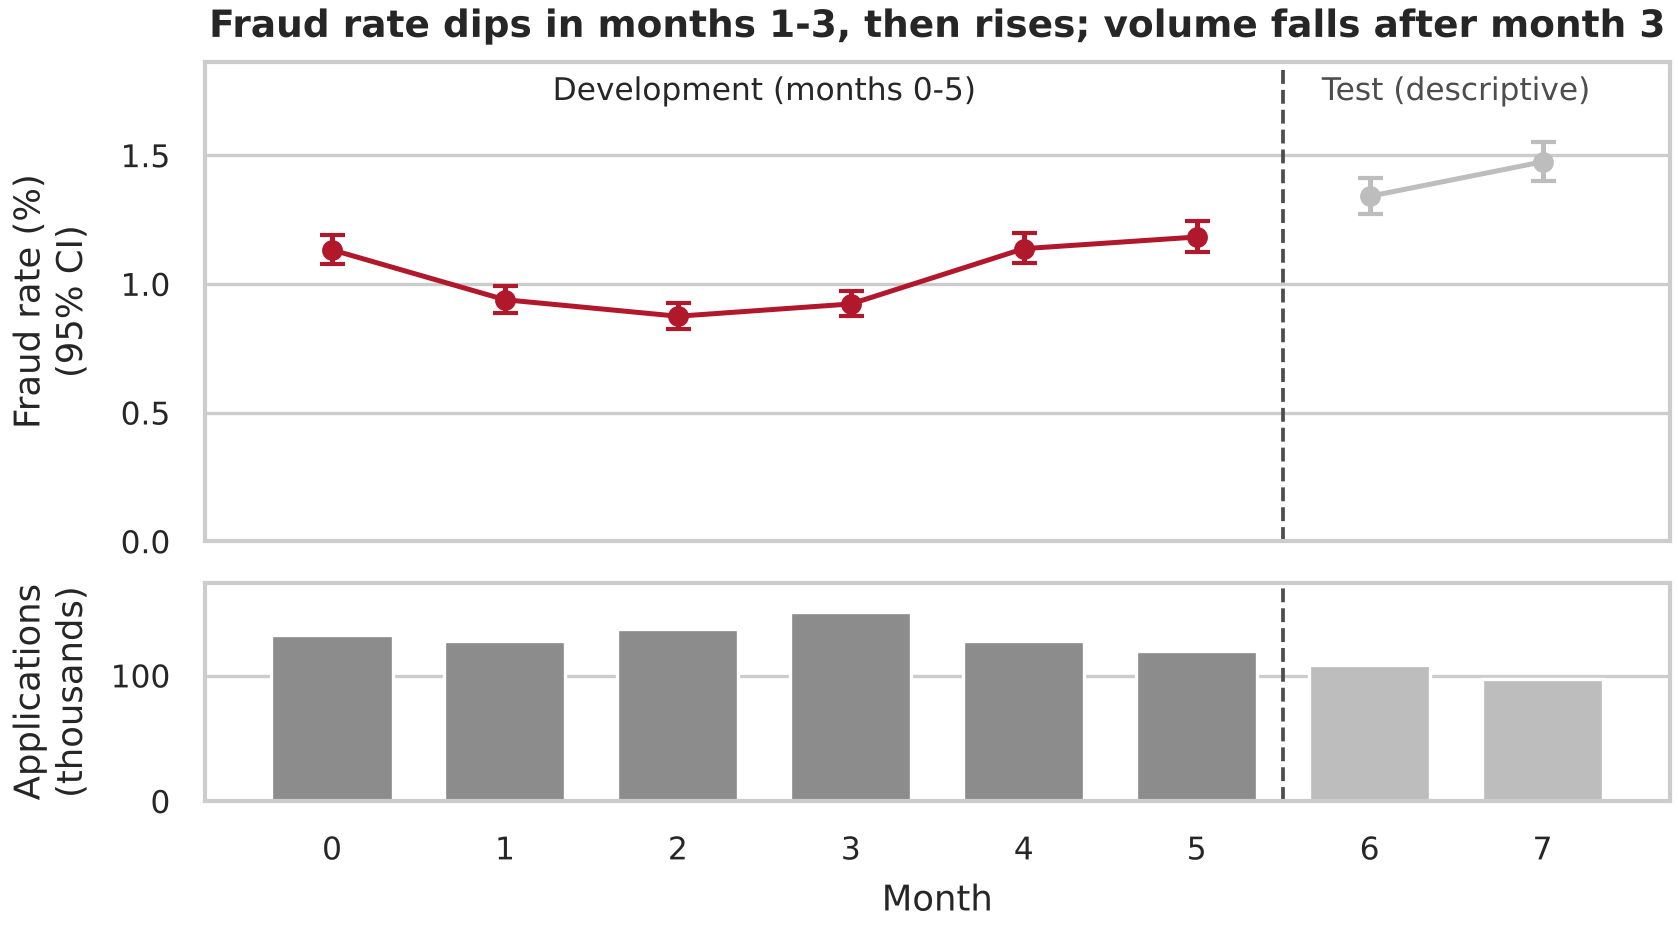

Chi-square across 8 months: chi2 = 330, df = 7, p = 2.2e-67


,n,frauds,rate,ci_low,ci_high,share
month,,,,,,
0,132440,1500,1.1326,1.0770,1.1910,13.2440
1,127620,1198,0.9387,0.8873,0.9931,12.7620
2,136979,1198,0.8746,0.8266,0.9253,13.6979
3,150936,1392,0.9222,0.8753,0.9717,15.0936
4,127691,1452,1.1371,1.0804,1.1968,12.7691
5,119323,1411,1.1825,1.1227,1.2454,11.9323
6,108168,1450,1.3405,1.2737,1.4108,10.8168
7,96843,1428,1.4746,1.4005,1.5524,9.6843


In [6]:
show(eda.save_figure(eda.plot_fraud_by_month(df), "fig02_fraud_rate_by_month", FIG_DIR))

monthly = eda.fraud_rate_table(df, "month")
monthly.to_csv(TABLE_DIR / "eda_monthly.csv")

# Is the month-to-month change in fraud rate more than chance? (chi-square test)
from scipy.stats import chi2_contingency
chi2, p_value, dof, _ = chi2_contingency(pd.crosstab(df["month"], df[eda.TARGET]))
print(f"Chi-square across 8 months: chi2 = {chi2:.0f}, df = {dof}, p = {p_value:.1e}")
monthly

**Finding 2 – the fraud rate changes from month to month.**
- The rate dips from 1.13% (month 0) to 0.87% (month 2), recovers to 1.18% by month 5, and continues to 1.34% and 1.47% in the test months.
- Volume rises to a peak of 151k in month 3, then falls to 97k in month 7.
- The month-to-month differences are far larger than chance (χ² = 330, df = 7, p ≈ 2×10⁻⁶⁷). The 95% intervals of month 2 and month 7, for example, do not overlap.

*Implication:*
- A random split would mix these periods and hide the change, so keep the temporal split (months 0–5 development, 6–7 test; A2-07).
- The threshold is set on validation months to hit 5% FPR (A2-14), as agreed in A1.
- Finding 12 shows that the features drift as well. Report the **realised** FPR on the test months next to the recall, not just the recall.

## 4. Missing values (development months)

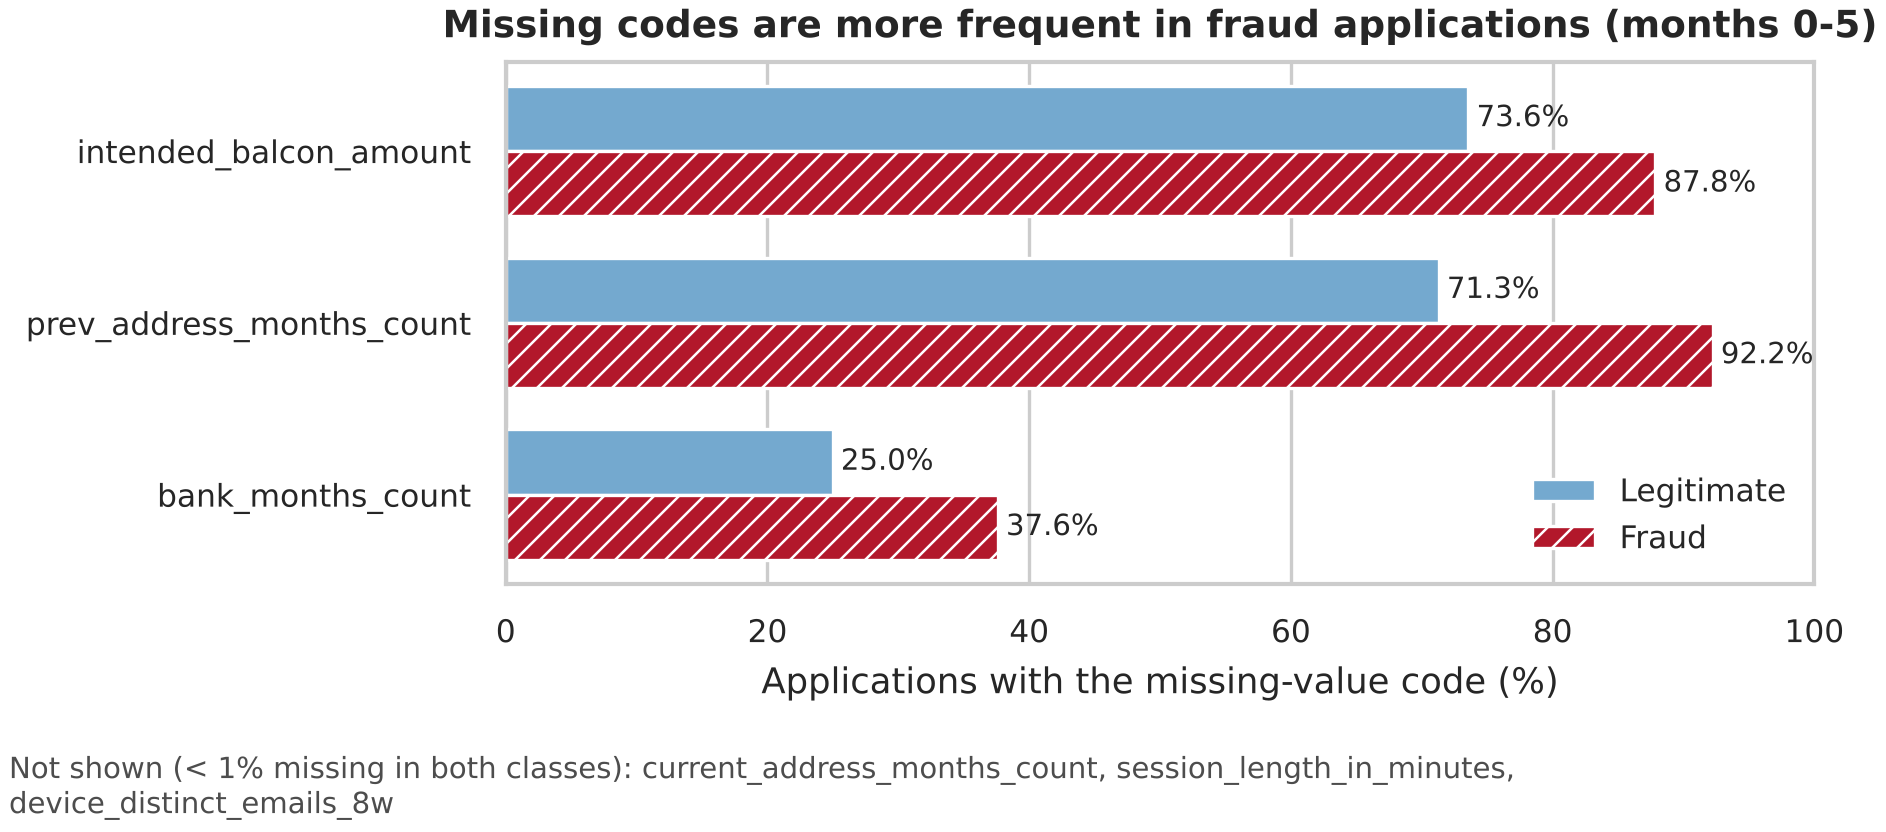

,n,share,rate,ci_low,ci_high
pattern,,,,,
prev_addr ok / balcon ok / bank_months ok,52138,6.5583,0.1208,0.0945,0.1546
prev_addr ok / balcon MISSING / bank_months ok,104460,13.1398,0.2575,0.2286,0.2901
prev_addr ok / balcon MISSING / bank_months MISSING,68455,8.6108,0.4309,0.3846,0.4829
prev_addr ok / balcon ok / bank_months MISSING,1513,0.1903,0.4627,0.2243,0.9519
prev_addr MISSING / balcon ok / bank_months ok,153097,19.2578,0.5748,0.5382,0.6139
prev_addr MISSING / balcon MISSING / bank_months ok,285745,35.9433,1.3561,1.3143,1.3992
prev_addr MISSING / balcon ok / bank_months MISSING,2333,0.2935,1.7574,1.2981,2.3753
prev_addr MISSING / balcon MISSING / bank_months MISSING,127248,16.0063,2.1383,2.0603,2.2193


In [7]:
show(eda.save_figure(eda.plot_missing_codes(dev), "fig03_missing_codes_by_class", FIG_DIR))

# Fraud rate for every combination of the three heavily-missing columns
pd.set_option("display.max_colwidth", 80)
patterns = eda.missing_pattern_table(dev)
patterns.to_csv(TABLE_DIR / "eda_missing_patterns.csv")
patterns[["n", "share", "rate", "ci_low", "ci_high"]]

**Finding 3 – missingness is informative, not random.**

Share of applications with the missing code, legitimate vs fraud:

| Column | Legitimate | Fraud |
|---|---|---|
| `prev_address_months_count` | 71.3% | 92.2% |
| `intended_balcon_amount` | 73.6% | 87.8% |
| `bank_months_count` | 25.0% | 37.6% |

The other three coded columns are missing in under 0.5% of rows. The combinations matter even more (table above):
- all three present: 0.12% fraud;
- all three missing: 2.14% fraud, about 18× higher (16% of applications).

*Implication:*
- Never drop these rows or columns.
- For Logistic Regression, impute (median fitted on the training months) **and** add a 0/1 "was missing" flag for each of the three columns.
- Tree models can use the raw −1 code directly, since it is already a separate value.
- For `intended_balcon_amount`, the negative values are many distinct amounts, not one code. Keep the flag and the value.

## 5. Categorical and binary features (development months)

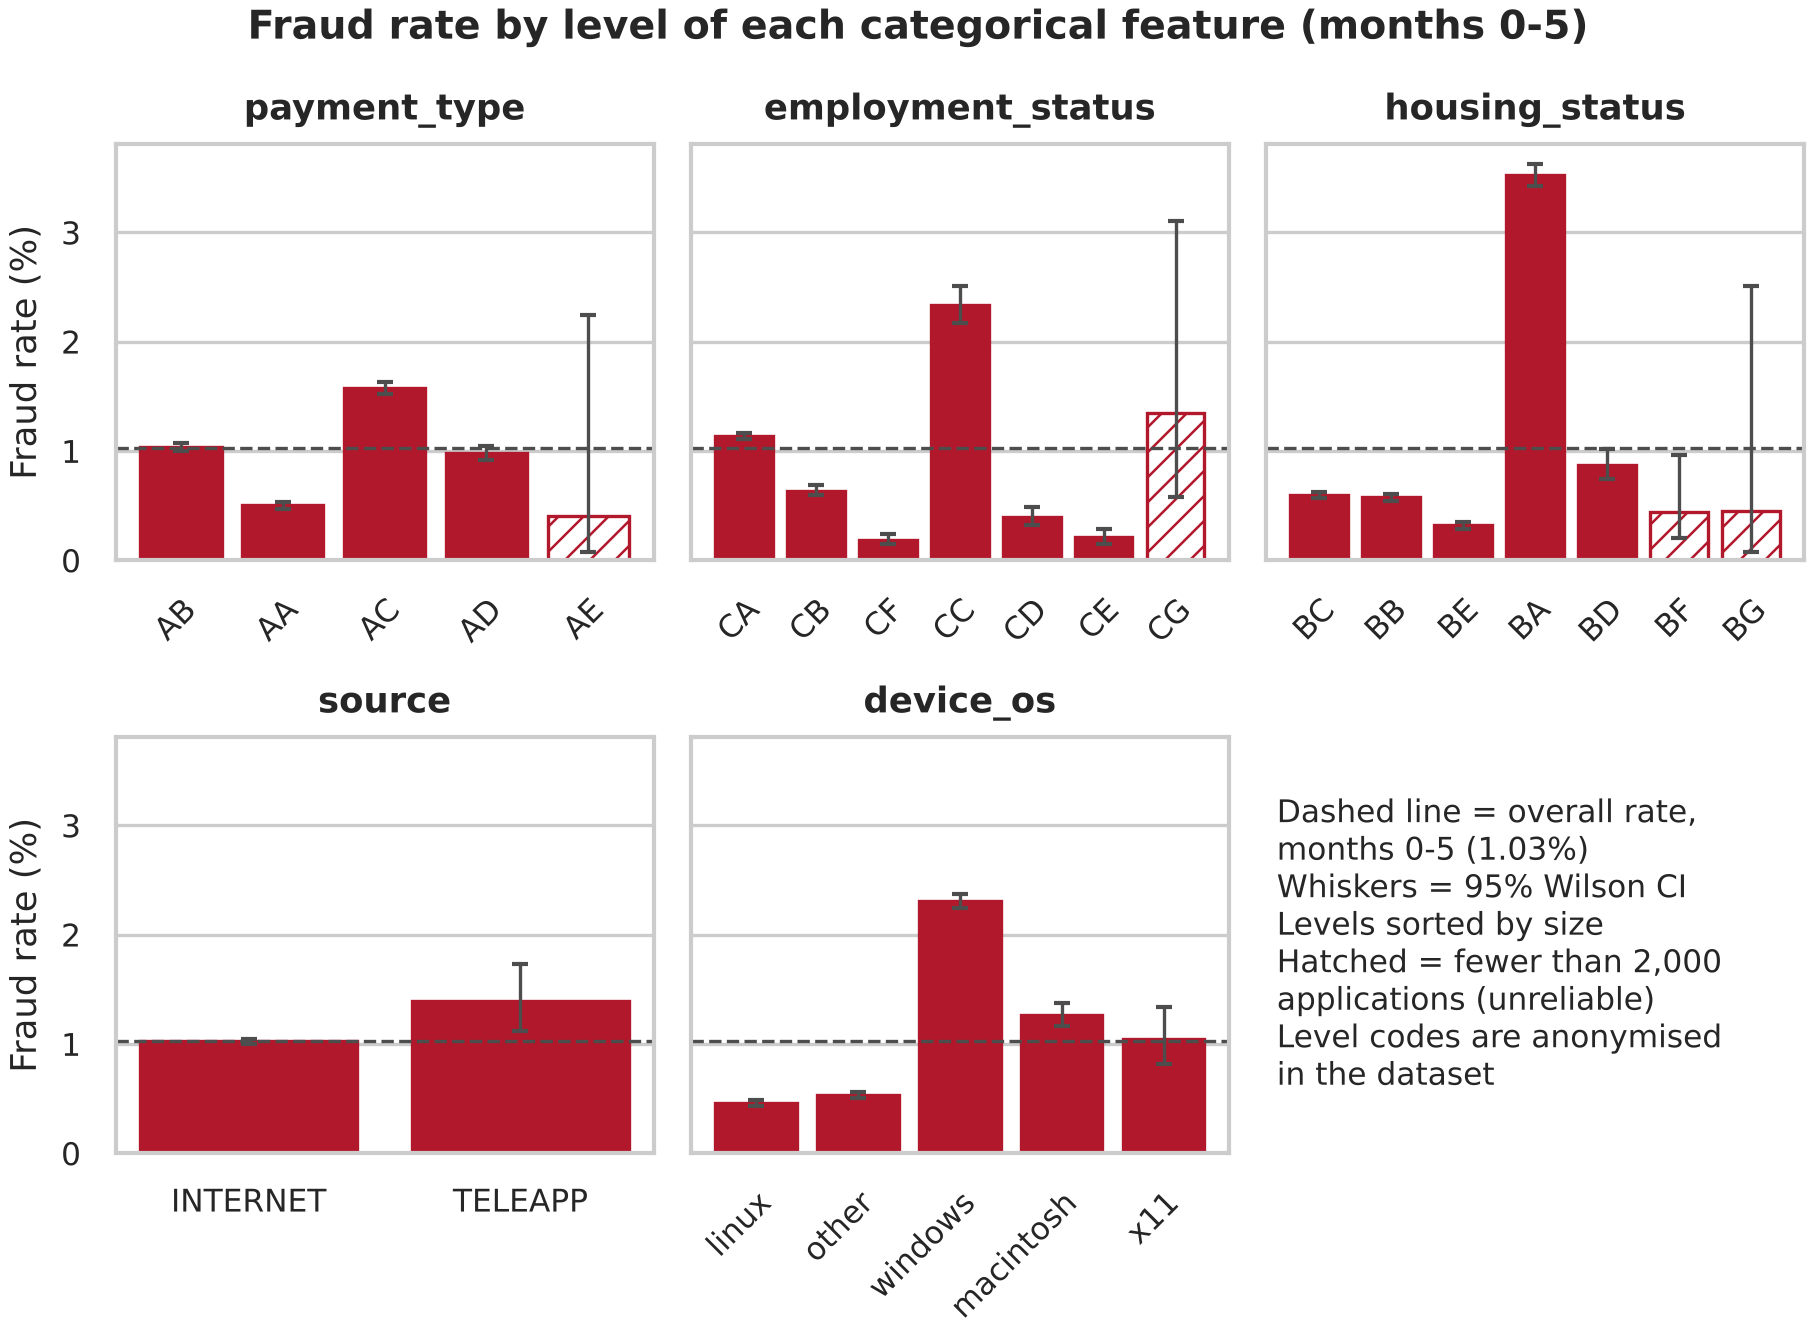

,,n,frauds,rate,ci_low,ci_high,share
feature,level,,,,,,
housing_status,BA,129775,4571,3.5223,3.4233,3.6239,16.3241
employment_status,CC,31247,730,2.3362,2.1745,2.5097,3.9305
device_os,windows,212925,4905,2.3036,2.2408,2.3682,26.7834
payment_type,AC,198579,3134,1.5782,1.5243,1.6340,24.9788
source,TELEAPP,5737,80,1.3945,1.1219,1.7321,0.7216
employment_status,CG,372,5,1.3441,0.5754,3.1074,0.0468
device_os,macintosh,43011,544,1.2648,1.1634,1.3748,5.4103
employment_status,CA,571543,6486,1.1348,1.1077,1.1626,71.8932


In [8]:
show(eda.save_figure(eda.plot_fraud_rate_by_category(dev), "fig04_fraud_rate_by_category", FIG_DIR))

levels = pd.concat({c: eda.fraud_rate_table(dev, c) for c in eda.CATEGORICAL}, names=["feature", "level"])
levels.to_csv(TABLE_DIR / "eda_category_levels.csv")
levels.sort_values("rate", ascending=False).head(8)

**Finding 4 – some category levels are strong risk markers.**

Against an overall development fraud rate of 1.03%, the riskiest large levels are:

| Level | Fraud rate | Share of applications |
|---|---|---|
| `housing_status = BA` | 3.5% (3.4×) | 16% |
| `employment_status = CC` | 2.3% | 4% |
| `device_os = windows` | 2.3% | 27% |
| `payment_type = AC` | 1.6% | 25% |

- `source` barely matters: TELEAPP is 1.4%, but only 0.7% of applications come through it.
- Levels AE, CG, BF and BG each have fewer than 2,000 rows (hatched in the figure), so their intervals are wide.
- The level codes are anonymised in BAF, so they cannot be given real-world meanings.

*Implication:*
- One-hot encode the five categoricals for Logistic Regression. LightGBM/XGBoost can use them natively.
- Merge rare levels into "other", with the level list fitted on the training months.
- K-Means (A2-12) needs its own encoding decision, because dummy columns distort distances.

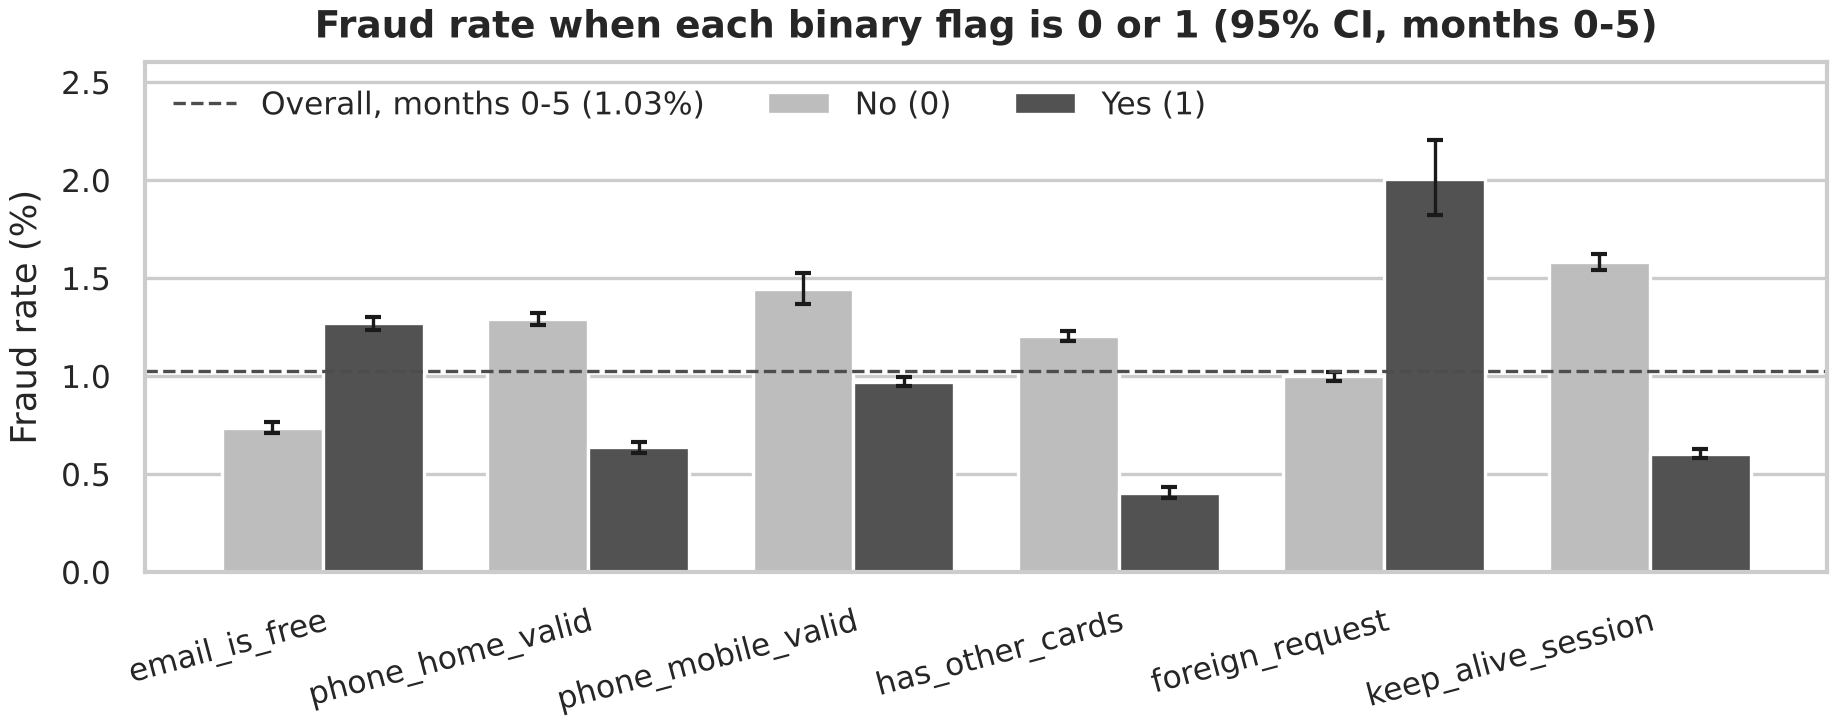

n   share   rate
flag               value                       
email_is_free      0      364146 45.8052 0.7373
                   1      430843 54.1948 1.2687
phone_home_valid   0      473148 59.5163 1.2903
                   1      321841 40.4837 0.6357
phone_mobile_valid 0       91319 11.4868 1.4455
                   1      703670 88.5132 0.9708
has_other_cards    0      616722 77.5762 1.2046
                   1      178267 22.4238 0.4050
foreign_request    0      774326 97.4008 0.9992
                   1       20663  2.5992 2.0036
keep_alive_session 0      342571 43.0913 1.5824
                   1      452418 56.9087 0.6034

In [9]:
show(eda.save_figure(eda.plot_binary_flags(dev), "fig05_fraud_rate_by_binary_flag", FIG_DIR))

flags = pd.concat({c: eda.fraud_rate_table(dev, c) for c in eda.BINARY_FLAGS}, names=["flag", "value"])
flags.to_csv(TABLE_DIR / "eda_binary_flags.csv")
flags[["n", "share", "rate"]]

**Finding 5 – several yes/no flags change fraud risk by 2–3×.**

| Flag | Fraud rate when 1 | Fraud rate when 0 | Note |
|---|---|---|---|
| `has_other_cards` | 0.41% | 1.20% | about 3× lower when 1 |
| `keep_alive_session` | 0.60% | 1.58% | |
| `phone_home_valid` | 0.64% | 1.29% | |
| `foreign_request` | 2.00% | 1.00% | only 2.6% of applications |
| `email_is_free` | 1.27% | 0.74% | |
| `phone_mobile_valid` | 0.97% | 1.45% | weakest effect |

*Implication:* keep the flags as 0/1 features; they need no scaling. For K-Means and Isolation Forest, decide explicitly whether to standardise them with the continuous features, since that changes their weight.

## 6. Numeric features (development months)

In [10]:
# Rank continuous features by fraud vs legitimate separation (KS distance)
num_features = eda.numeric_features(dev)
continuous = [c for c in num_features if dev[c].nunique() > 50]
sep = eda.numeric_separation_table(dev, continuous)
sep.to_csv(TABLE_DIR / "eda_numeric_separation.csv", index=False)
sep

,feature,missing_pct,median_legit,median_fraud,ks_statistic
0,current_address_months_count,0.4000,53.0000,93.0000,0.2611
1,credit_risk_score,0.0000,119.0000,174.0000,0.2560
2,name_email_similarity,0.0000,0.5009,0.2933,0.1902
3,bank_branch_count_8w,0.0000,10.0000,2.0000,0.1697
4,prev_address_months_count,71.5000,32.0000,50.0000,0.1542
5,intended_balcon_amount,73.7000,32.5977,35.2501,0.0790
6,days_since_request,0.0000,0.0153,0.0133,0.0655
7,velocity_4w,0.0000,5118.0183,5032.5225,0.0507
8,velocity_6h,0.0000,5965.2119,5604.9924,0.0501
9,zip_count_4w,0.0000,1360.0000,1451.0000,0.0465


In [11]:
# Share of each class above the pooled 99th percentile (these rows are not drawn in Fig 6)
tail = pd.DataFrame({c: [(dev.loc[dev[eda.TARGET] == k, c] > dev[c].quantile(0.99)).mean() * 100 for k in (0, 1)]
                     for c in continuous}, index=["legit_%", "fraud_%"]).T
tail.sort_values("fraud_%", ascending=False).head(5)

,legit_%,fraud_%
credit_risk_score,0.9363,5.8766
session_length_in_minutes,0.9908,1.8893
current_address_months_count,0.9478,1.3618
days_since_request,0.9984,1.1532
zip_count_4w,1.0000,0.8956


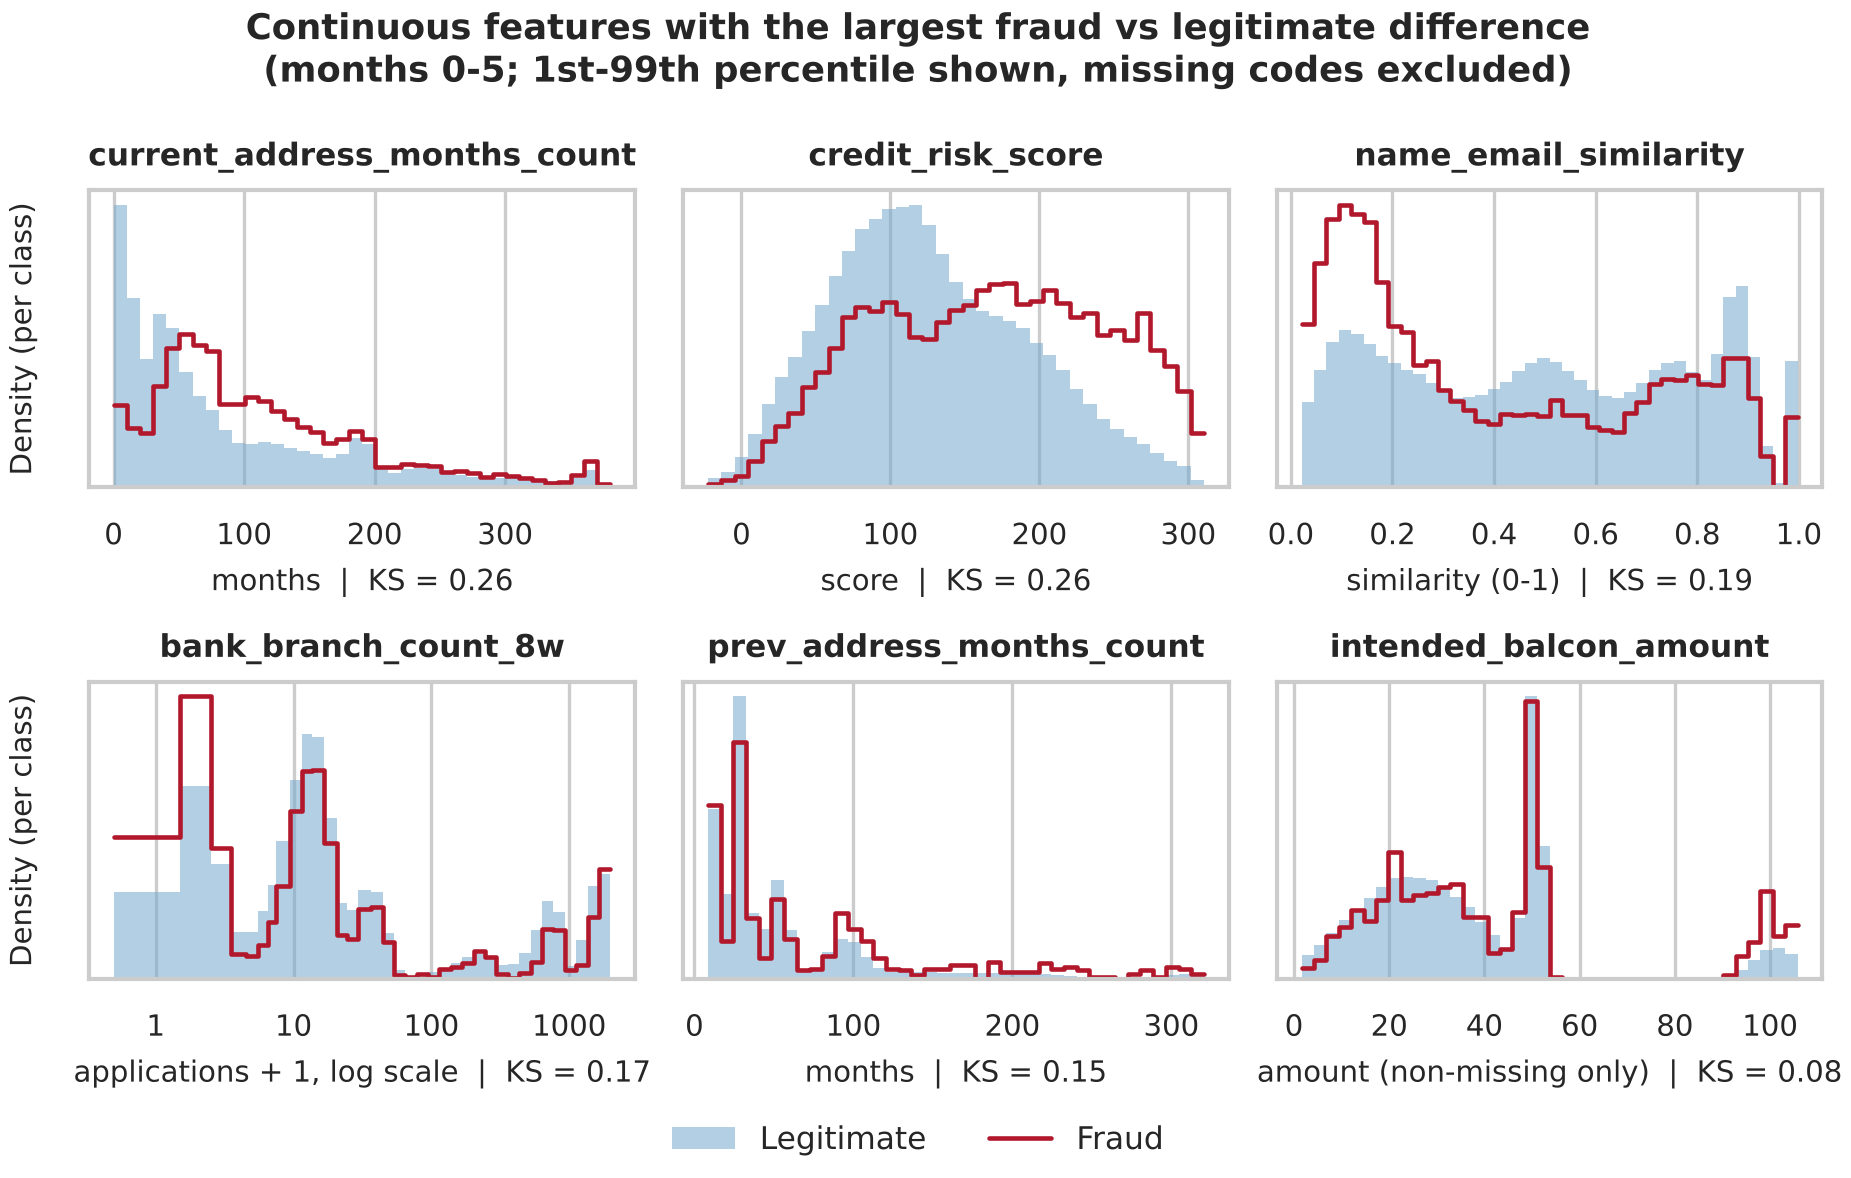

In [12]:
# Distributions of the 6 continuous features with the largest KS distance
top_numeric = list(sep["feature"][:6])
fig = eda.plot_numeric_distributions(dev, top_numeric, ks=dict(zip(sep["feature"], sep["ks_statistic"])))
show(eda.save_figure(fig, "fig06_numeric_distributions_top6", FIG_DIR))

**Finding 6 – which continuous features separate the classes.**

Ranked by KS distance (0 = same distribution, 1 = fully separated):

| Feature | KS | Median, legitimate | Median, fraud |
|---|---|---|---|
| `current_address_months_count` | 0.26 | 53 | 93 |
| `credit_risk_score` | 0.26 | 119 | 174 |
| `name_email_similarity` | 0.19 | 0.50 | 0.29 |
| `bank_branch_count_8w` | 0.17 | 10 | 2 |
| `prev_address_months_count` | 0.15 | 32 | 50 |

- `prev_address_months_count` is tested on its 28.5% non-missing rows only, because KS cannot see missingness.
- The velocity features, `zip_count_4w`, `session_length_in_minutes`, `days_since_request` and `intended_balcon_amount` barely differ (KS ≤ 0.08).
- The discrete features (age, income, credit limit) are shown as rates in Figures 9–10.

**Finding 7 – what the distributions look like (Figure 6).** Fraud applications have:
- lower `name_email_similarity`, with a peak near 0.1–0.2 where the name does not match the email;
- higher `credit_risk_score`, shifted right across the whole range; 5.9% of fraud vs 0.9% of legitimate applications score above the 99th percentile (305);
- longer time at the current address;
- far fewer branch applications in the last 8 weeks.

Several shapes are multi-modal (`bank_branch_count_8w`, `prev_address_months_count`).

*Implication:*
- Tree ensembles can follow these shapes and the missing codes directly, so compare them against the Logistic Regression baseline (A2-11).
- The marginal shapes alone do not prove a large gain, so expect a modest one.
- For Logistic Regression, scale the features and log-transform the skewed counts.

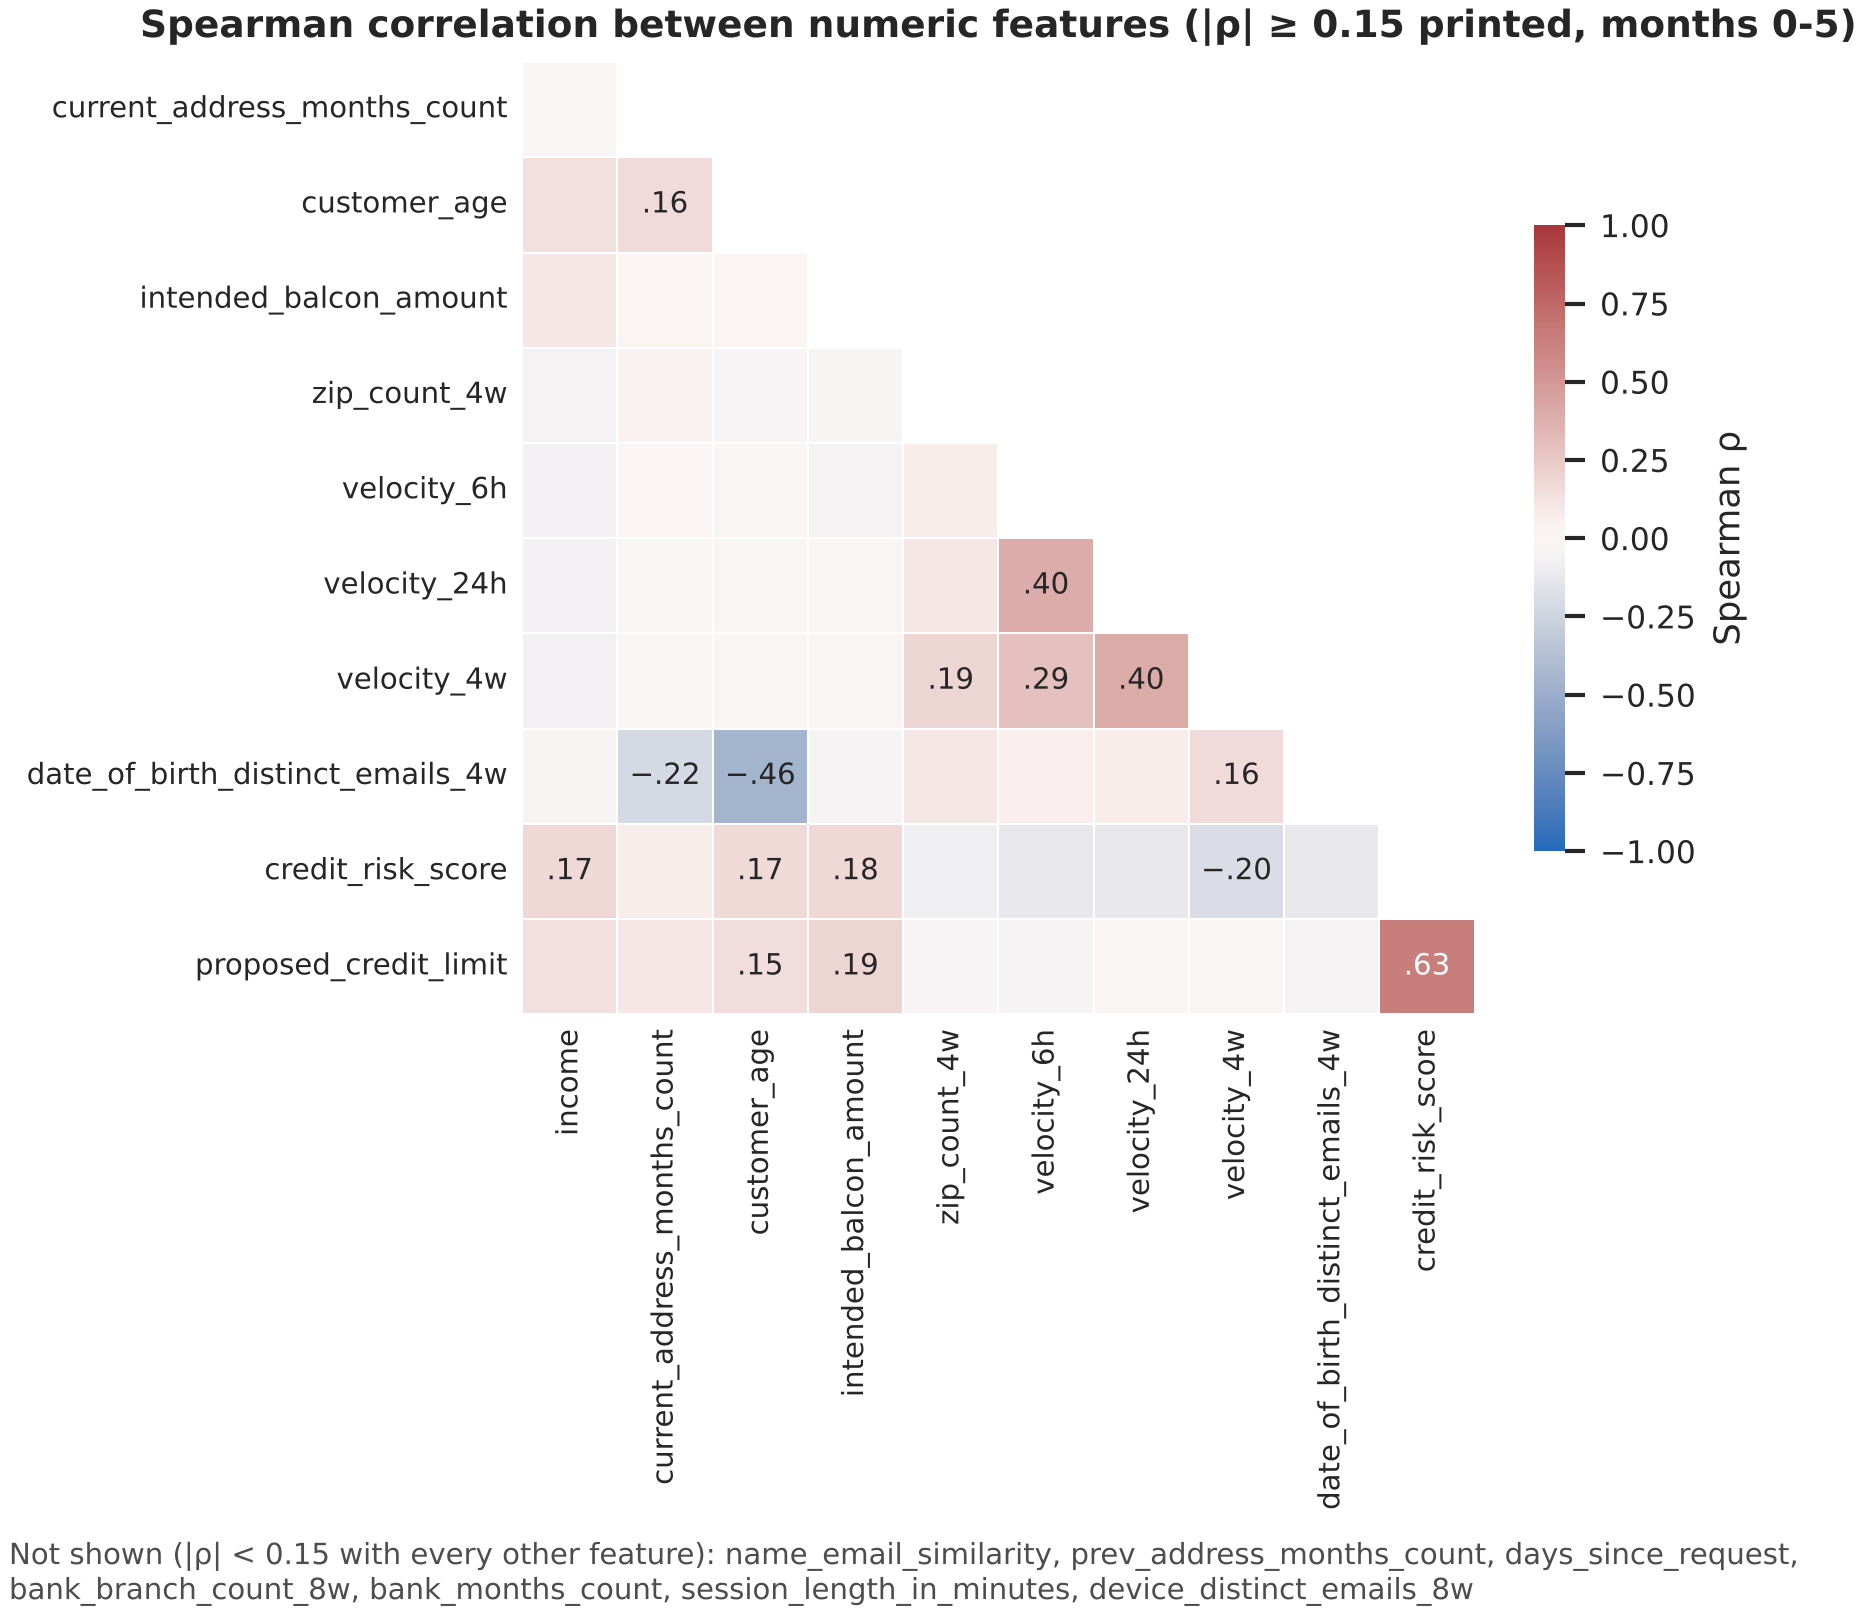

,feature_a,feature_b,rho
0,credit_risk_score,proposed_credit_limit,0.6344
1,customer_age,date_of_birth_distinct_emails_4w,-0.4563
2,velocity_24h,velocity_4w,0.4027


In [13]:
# Feature-feature correlation (computed once, reused for the figure and the pairs table)
corr = eda.spearman_matrix(dev, num_features)
show(eda.save_figure(eda.plot_correlations(corr), "fig07_spearman_correlation", FIG_DIR))

strong_pairs = eda.correlated_pairs(corr)            # |rho| >= 0.40
strong_pairs.to_csv(TABLE_DIR / "eda_strong_correlations.csv", index=False)
strong_pairs

**Finding 8 – little redundancy between features.**

Only three pairs reach |ρ| ≥ 0.40 (table above):
- `credit_risk_score` and `proposed_credit_limit`: 0.63.
- `customer_age` and `date_of_birth_distinct_emails_4w`: −0.46. Older applicants share their birth date with fewer emails.
- `velocity_24h` and `velocity_4w`: 0.40.

`velocity_6h` and `velocity_24h` sit just below, at 0.397 (shown rounded as .40 in Figure 7). No pair is close to ±1.

*Implication:*
- Keep all features. Collinearity is only a mild concern for the Logistic Regression coefficients, and none for tree models.
- `device_fraud_count` is constant (always 0) and is dropped, so the model has 29 input features, not 30. The A3 form and API contract (A2-19) should note this.

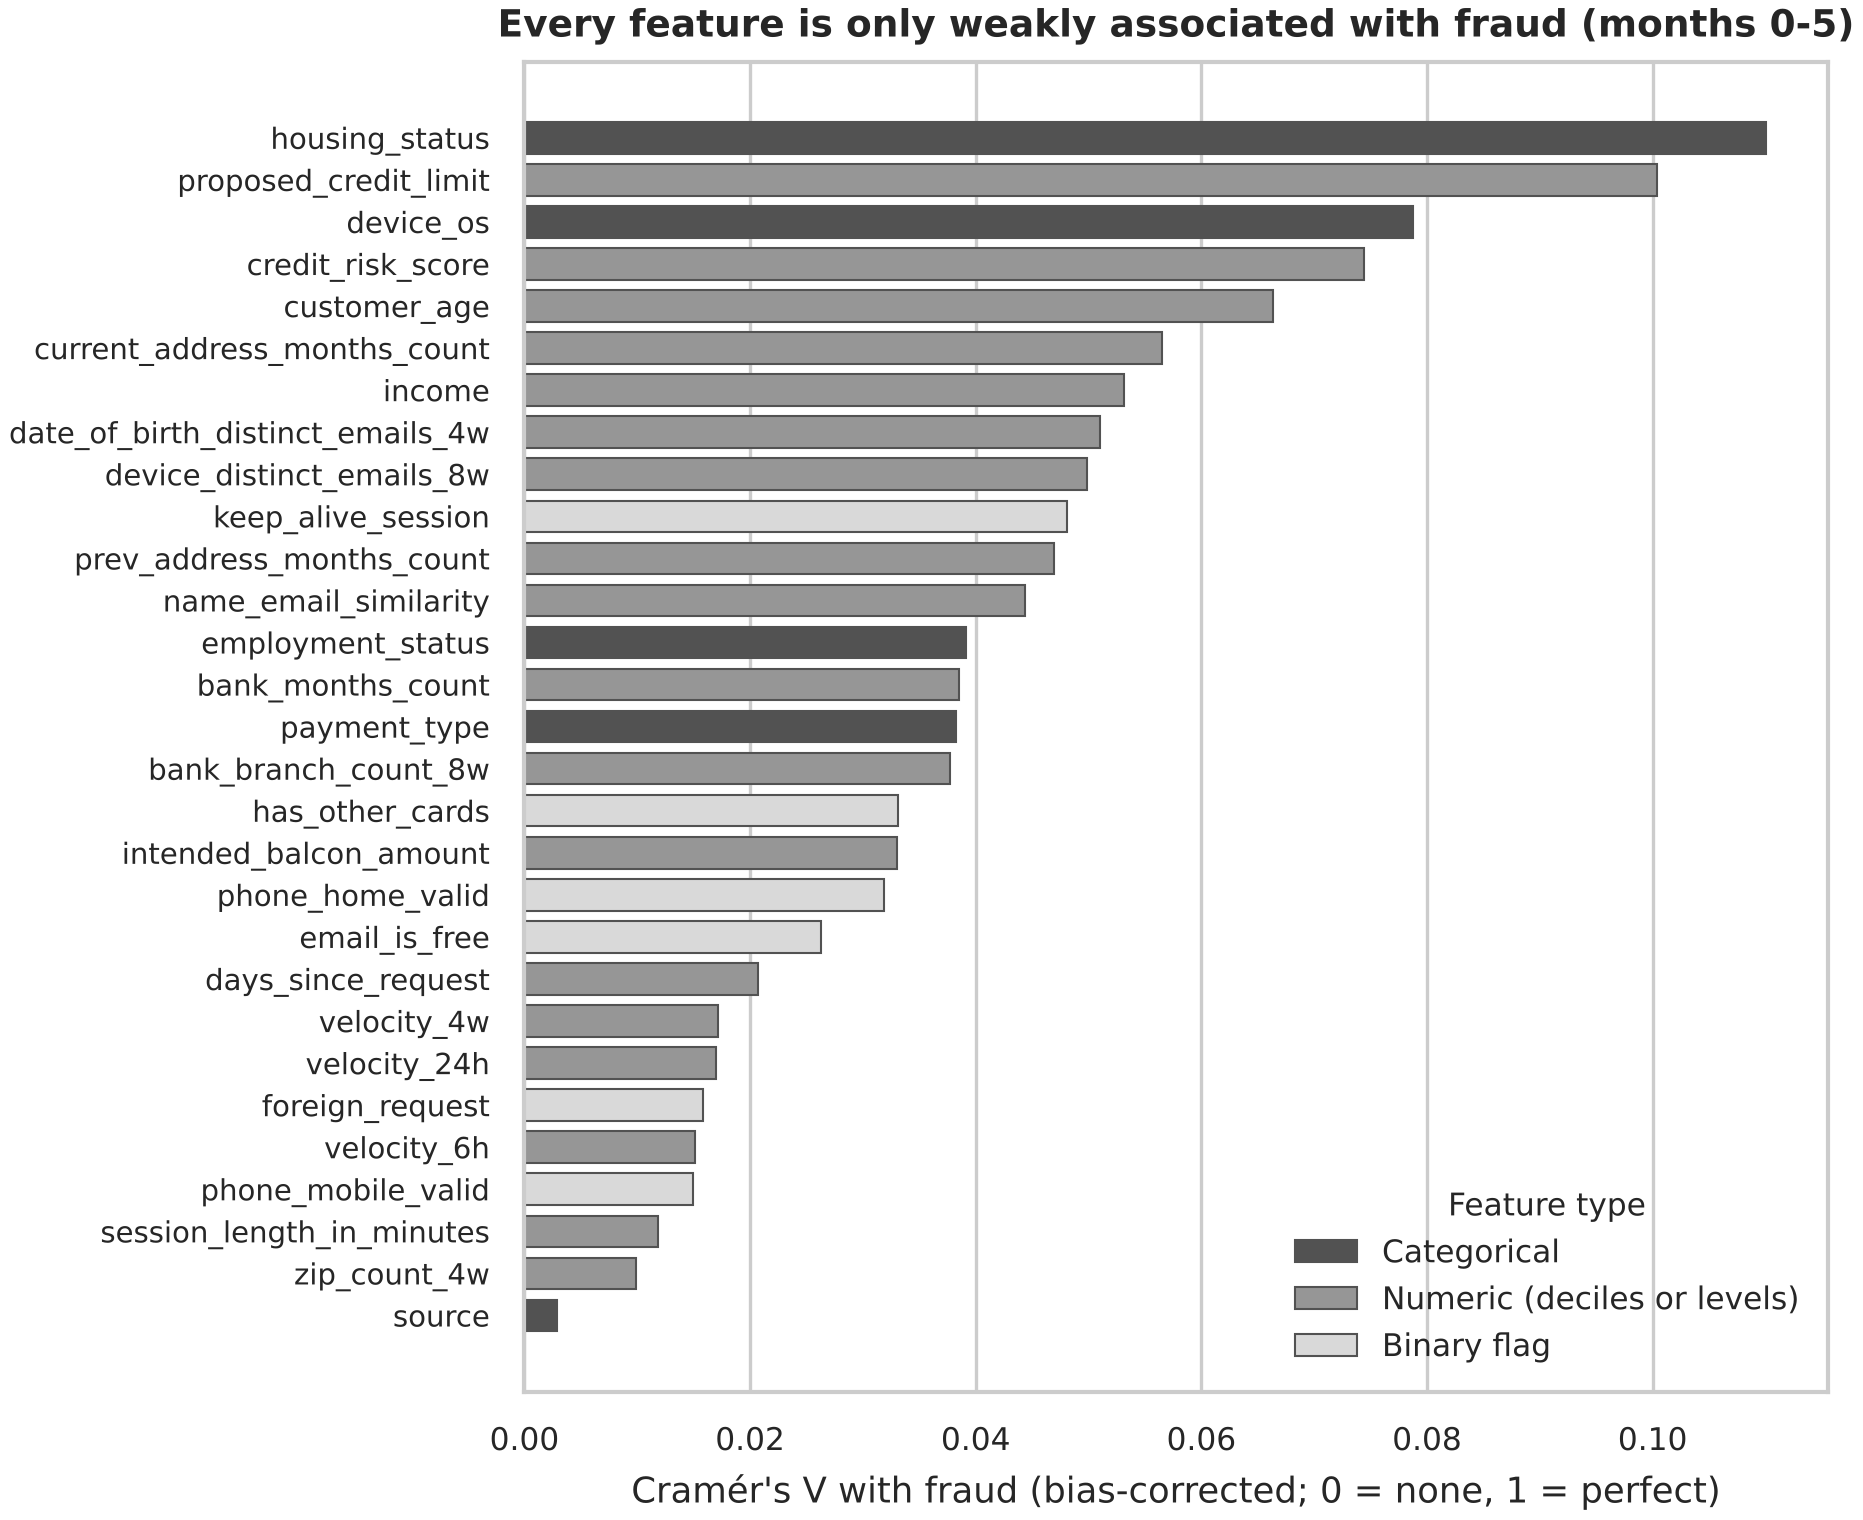

,feature,recall_at_5pct_fpr
0,credit_risk_score,0.2063
1,housing_status,0.1762
2,date_of_birth_distinct_emails_4w,0.1675
3,proposed_credit_limit,0.1621
4,customer_age,0.1515
5,device_distinct_emails_8w,0.1377
6,device_os,0.1138
7,employment_status,0.1021


In [14]:
# One comparable association metric for every feature (Cramer's V; numeric binned into deciles)
assoc = eda.association_table(dev, num_features)
assoc.to_csv(TABLE_DIR / "eda_feature_association.csv", index=False)
show(eda.save_figure(eda.plot_target_association(assoc), "fig08_feature_association_with_fraud", FIG_DIR))

# The benchmark metric for a ONE-feature rule: recall at 5% false-positive rate
single = eda.single_feature_recall(dev, eda.CATEGORICAL + eda.BINARY_FLAGS + num_features)
single.to_csv(TABLE_DIR / "eda_single_feature_recall.csv", index=False)
single.head(8)

**Finding 9 – no single feature is enough.**
- Using one metric for every feature, the strongest association is `housing_status` (Cramér's V = 0.11), followed by `proposed_credit_limit` (0.10) and `device_os` (0.08). Every feature is weak on its own.
- The benchmark metric says the same. Used alone as a score, the best single feature (`credit_risk_score`) catches only **20.6%** of fraud at 5% FPR. Next come `housing_status` (17.6%), `date_of_birth_distinct_emails_4w` (16.7%) and `proposed_credit_limit` (16.2%); a random rule would catch 5%.
- Even the two strongest categoricals combined (`housing_status` × `device_os`) reach only 32.5%.

*Implication:* simple rules on one or two fields would miss most fraud, which is the quantitative case for a multivariate ML model in Problem Framing (A2-25). These recalls are also the floor every model in A2-11 must clear.

## 7. Age and the fairness check (development months)

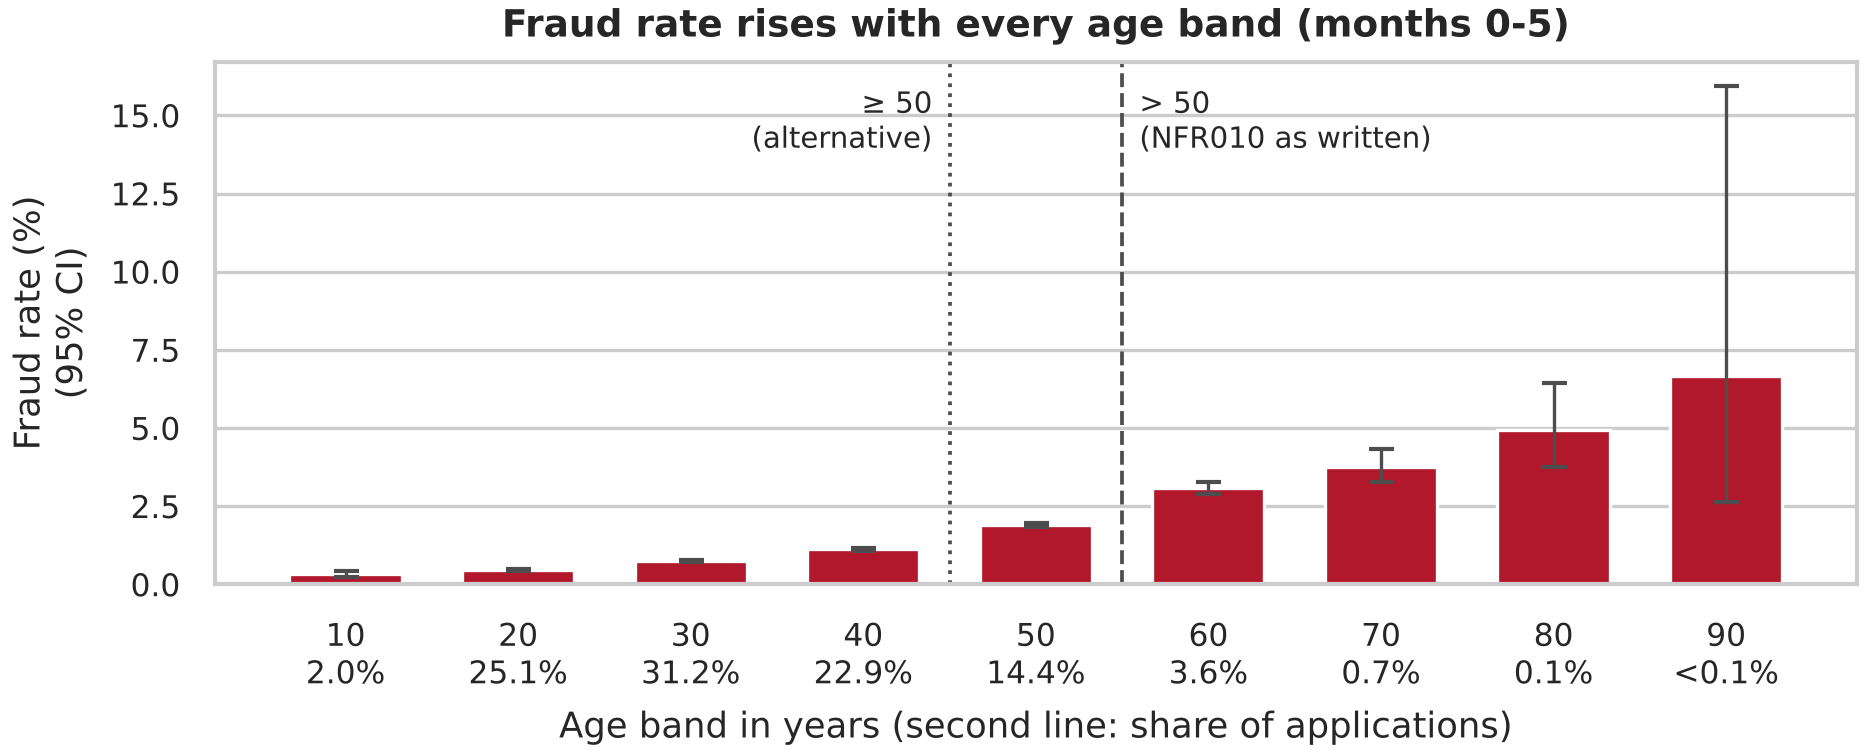

,definition,group,applications,share_pct,fraud_rate_pct,rate_ratio_older_vs_younger
0,age > 50,older,34557,4.3469,3.2439,3.5089
1,age > 50,younger,760432,95.6531,0.9245,3.5089
2,age >= 50,older,149234,18.7718,2.2086,2.9376
3,age >= 50,younger,645755,81.2282,0.7518,2.9376


In [15]:
show(eda.save_figure(eda.plot_fraud_by_age(dev), "fig09_fraud_rate_by_age", FIG_DIR))

age_groups = eda.age_split_table(dev)
age_groups.to_csv(TABLE_DIR / "eda_age_groups.csv", index=False)
age_groups

**Finding 10 – age is strongly linked to fraud, which matters for fairness.**
- Fraud rises with every age band, from 0.3% at age 10 to about 5% at age 80.
- `customer_age` comes in decade bands, so the A1 rule ">50 vs ≤50" (NFR010) means **60 and over**.

The two possible fairness groups (table above):

| Definition | Share of dev applications | Fraud rate, older | Fraud rate, younger | Ratio |
|---|---|---|---|---|
| > 50 (60+) | 4.3% | 3.24% | 0.92% | 3.5× |
| ≥ 50 (50+) | 18.8% | 2.21% | 0.75% | 2.9× |

The BAF paper describes its age split as roughly 80/20, which only "≥ 50" reproduces here, and later BAF work uses "50 and above". The A1 rule says "> 50". **The team must confirm one definition before A2-16** and use it everywhere (NFR010, A2-16, report).

*Implication:*
- Any model will score older applicants as riskier, so their false-positive rate will likely be higher at the chosen threshold. That is what the predictive-equality check (FPR ratio) in A2-16 measures.
- Removing `customer_age` would not fix this: `date_of_birth_distinct_emails_4w` is correlated with age (ρ = −0.46) and acts as a proxy.
- `income` and `employment_status` are the other protected attributes in BAF; their fraud rates differ too (Findings 4 and 11).

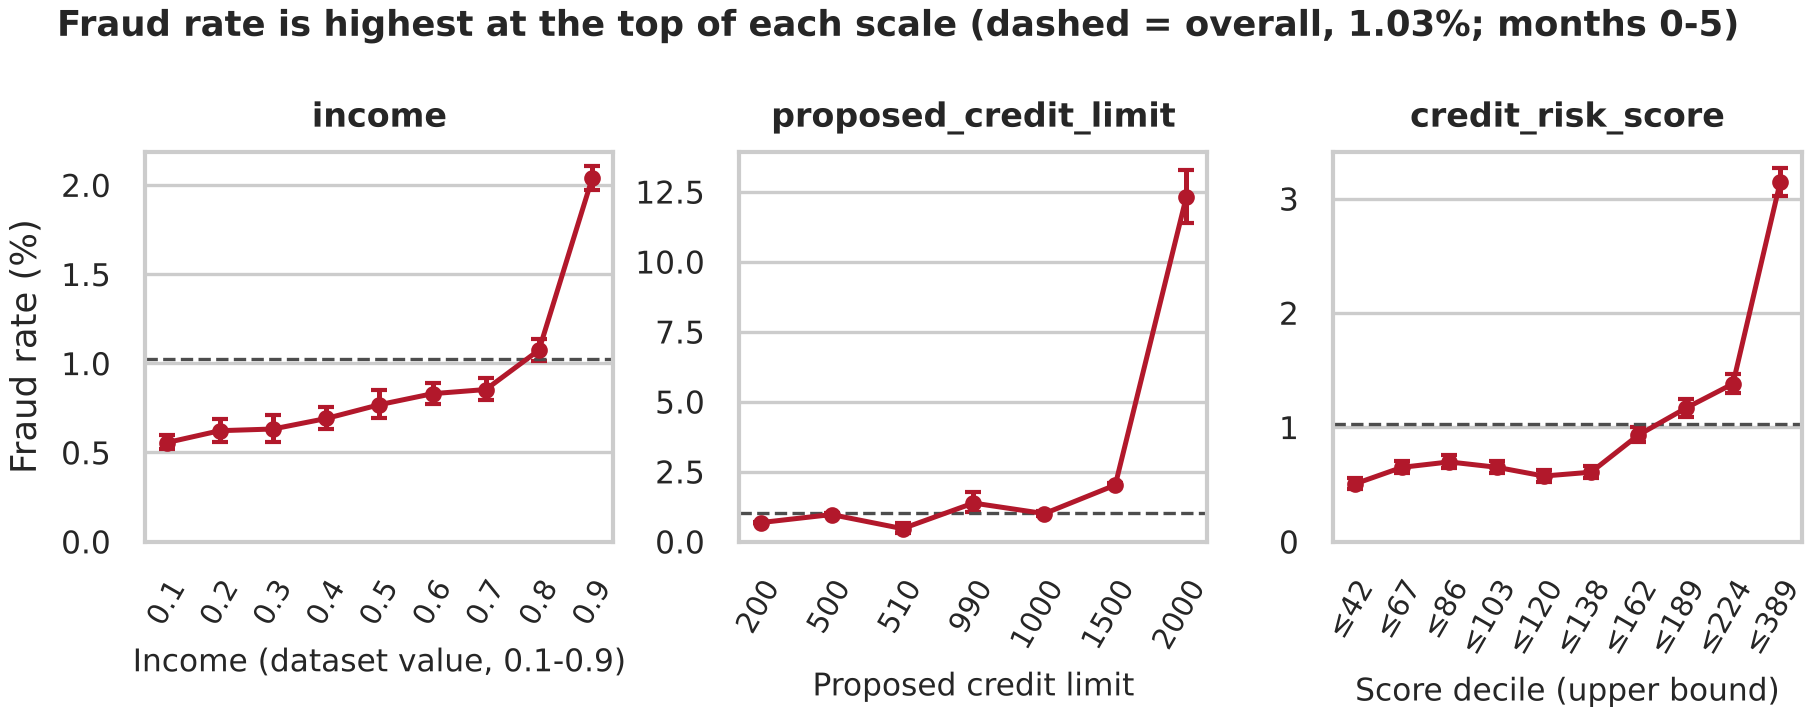

n    rate  ci_low  ci_high
feature               value                                     
income                0.1000     134849  0.5547  0.5164   0.5958
                      0.2000      58068  0.6217  0.5609   0.6890
                      0.3000      42305  0.6311  0.5600   0.7112
                      0.4000      66802  0.6901  0.6301   0.7558
                      0.5000      45604  0.7675  0.6914   0.8518
                      0.6000      89948  0.8294  0.7722   0.8908
                      0.7000      82920  0.8526  0.7923   0.9175
                      0.8000     112291  1.0740  1.0154   1.1360
                      0.9000     162202  2.0376  1.9700   2.1075
proposed_credit_limit 190.0000       85  0.0000  0.0000   4.3241
                      200.0000   488926  0.6760  0.6534   0.6993
                      210.0000      552  0.1812  0.0320   1.0190
                      490.0000      377  1.0610  0.4134   2.6960
                      500.0000   101502  0.9635  0.9053   1.0255
                      510.0000     6081  0.4605  0.3188   0.6647
                      990.0000     4220  1.3744  1.0647   1.7725
                      1000.0000   61077  0.9971  0.9213   1.0790
                      1500.0000  127369  2.0178  1.9420   2.0964
                      1900.0000     208 15.8654 11.5256  21.4432
                      2000.0000    4554 12.2969 11.3747  13.2826
                      2100.0000      38 13.1579  5.7538  27.3272

In [16]:
show(eda.save_figure(eda.plot_ordinal_features(dev), "fig10_fraud_rate_ordinal_features", FIG_DIR))

ordinal = pd.concat({c: eda.fraud_rate_table(dev, c) for c in ["income", "proposed_credit_limit"]},
                    names=["feature", "value"])
ordinal.to_csv(TABLE_DIR / "eda_ordinal_features.csv")
ordinal[["n", "rate", "ci_low", "ci_high"]]

**Finding 11 – risk is highest at the top of the financial scales.** Only large levels (n ≥ 2,000) are shown.
- **`income`:** fraud rises steadily from 0.55% at 0.1 to 2.04% at 0.9.
- **`proposed_credit_limit`:** fraud is 0.68% at 200, 2.0% at 1,500 and 12.3% at 2,000 (n = 4,554). The 1,900 and 2,100 levels are similar but tiny (n = 208 and 38).
- **`credit_risk_score`:** fraud is flat at about 0.5–0.7% across the bottom six deciles, then climbs to 3.1% in the top decile (above 224).

These threshold-like steps suit tree models, and they give the fraud analyst readable reasons in the A3 dashboard.

## 8. Drift inside the development months

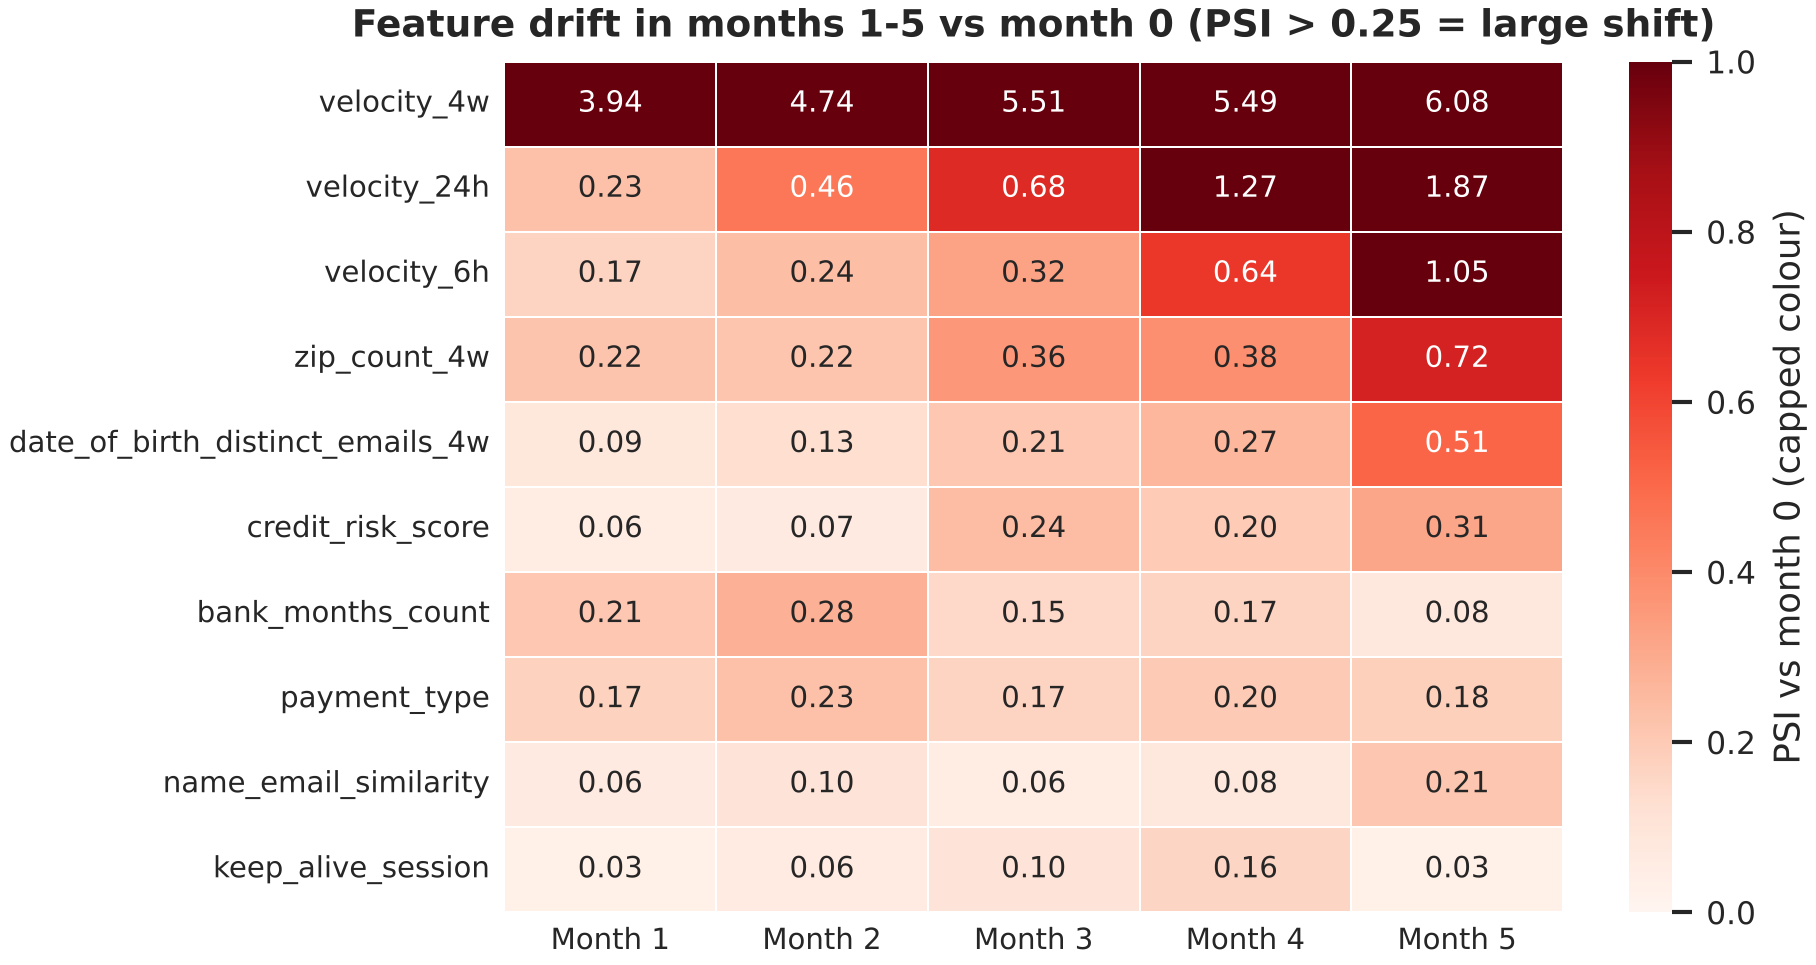

,month_1,month_2,month_3,month_4,month_5,max_psi
feature,,,,,,
velocity_4w,3.9429,4.7382,5.5105,5.4898,6.0812,6.0812
velocity_24h,0.2321,0.4585,0.6847,1.2676,1.8655,1.8655
velocity_6h,0.1657,0.2383,0.3248,0.6391,1.0471,1.0471
zip_count_4w,0.2210,0.2153,0.3593,0.3837,0.7187,0.7187
date_of_birth_distinct_emails_4w,0.0889,0.1312,0.2094,0.2654,0.5136,0.5136
credit_risk_score,0.0553,0.0662,0.2430,0.1967,0.3127,0.3127
bank_months_count,0.2085,0.2847,0.1488,0.1692,0.0818,0.2847
payment_type,0.1730,0.2335,0.1690,0.2012,0.1830,0.2335
name_email_similarity,0.0645,0.1044,0.0577,0.0792,0.2135,0.2135


In [17]:
# Population Stability Index of every feature in months 1-5 against month 0
drift = eda.psi_table(dev, eda.CATEGORICAL + eda.BINARY_FLAGS + num_features)
drift.to_csv(TABLE_DIR / "eda_feature_drift_psi.csv")
show(eda.save_figure(eda.plot_feature_drift(drift), "fig11_feature_drift_psi", FIG_DIR))
drift.head(10)

In [18]:
# Does the RELATIONSHIP with fraud drift too? Lift of the top risk levels per month
risk = {"housing_status = BA": dev["housing_status"] == "BA",
        "device_os = windows": dev["device_os"] == "windows",
        "employment_status = CC": dev["employment_status"] == "CC",
        "keep_alive_session = 0": dev["keep_alive_session"] == 0,
        "proposed_credit_limit >= 1500": dev["proposed_credit_limit"] >= 1500}
base = dev.groupby("month")[eda.TARGET].mean()
lift = pd.DataFrame({name: dev[m].groupby(dev.loc[m, "month"])[eda.TARGET].mean() / base for name, m in risk.items()}).T
lift.to_csv(TABLE_DIR / "eda_risk_lift_by_month.csv")
print("velocity_4w median by month:", dev.groupby("month")["velocity_4w"].median().round(0).to_dict())
lift.round(2)

velocity_4w median by month: {0: 6344.0, 1: 5446.0, 2: 5462.0, 3: 4910.0, 4: 4696.0, 5: 4267.0}


month,0,1,2,3,4,5
housing_status = BA,3.1000,3.6600,4.1300,3.2900,3.2200,3.4700
device_os = windows,2.2100,2.1200,2.3300,2.4300,2.1700,2.2400
employment_status = CC,2.7500,2.3300,2.6600,1.9800,2.0900,2.1600
keep_alive_session = 0,1.7500,1.6100,1.5100,1.5000,1.4800,1.5200
proposed_credit_limit >= 1500,1.7800,1.8900,2.8700,2.5500,2.8900,2.7800


**Finding 12 – strong feature drift inside the development months.**

Several features change distribution even within months 0–5 (PSI against month 0; above 0.25 is a large shift by the usual rule of thumb):

| Feature | PSI in month 5 (vs month 0) | Note |
|---|---|---|
| `velocity_4w` | 6.08 | already 3.94 in month 1; median falls from 6,344 to 4,267, so it behaves almost like a clock |
| `velocity_24h` | 1.87 | |
| `velocity_6h` | 1.05 | |
| `zip_count_4w` | 0.72 | |
| `date_of_birth_distinct_emails_4w` | 0.51 | |
| `credit_risk_score` | 0.31 | step up from month 3 |

- `bank_months_count` (peak 0.28 in month 2) and `payment_type` (0.23) also move.
- The *relationship* with fraud is more stable than the distributions. The lift of the top risk levels stays within a limited band: `housing_status = BA` 3.1–4.1×, `device_os = windows` 2.1–2.4×, `keep_alive_session = 0` 1.5–1.75×.
- Two lifts do move: `employment_status = CC` varies from 2.75× (month 0) to 1.98× (month 3), and `proposed_credit_limit ≥ 1500` rises from 1.8× to 2.9×.

*Implication:*
- Validate on the **later** development months (e.g. train 0–3 or 0–4, validate 4–5 or 5), not on a random sample, so tuning sees the same kind of shift the test months will bring.
- Expect the test-month FPR to differ from the 5% set on validation, and report it (A2-14).
- The drifting velocity features may help short-term but transfer badly. A2-11 should compare models with and without them.

## 9. Summary – what the EDA means for the next tasks

| # | Finding | Action | Task |
|---|---|---|---|
| 1 | 1.03% fraud in dev (96.5 : 1) | Compare models on PR-AUC, recall at 5% FPR and F1; report accuracy too; class weights inside folds | A2-08, A2-11 |
| 2 | Fraud rate varies by month (χ² p ≈ 10⁻⁶⁷) | Keep temporal split; set threshold by FPR on validation months | A2-07, A2-14 |
| 3 | Missing codes far more common in fraud; all-missing pattern 18× riskier | Impute + missing flags for LR; raw codes for trees; never drop rows | A2-07 |
| 4–5 | Some levels / flags carry 2–3× risk | One-hot for LR (native for boosting); merge rare levels; keep 0/1 flags | A2-07 |
| 6–7 | Several continuous features separate classes, with non-linear shapes | Compare tree ensembles with the LR baseline; scale + log for LR | A2-11 |
| 8 | Low redundancy; one constant column | Keep features; drop `device_fraud_count` (29 inputs) | A2-07, A2-19 |
| 9 | Best single feature catches 20.6% at 5% FPR (two categoricals together 32.5%) | Quantitative case for ML over rules; floor every model must clear | A2-25, A2-11 |
| 10 | Age strongly linked to fraud; group definition open | Team confirms > 50 or ≥ 50; report FPR by age group; proxies exist | A2-16 |
| 11 | Risk steps up at the top of income / limit / risk score | Readable explanations for the analyst dashboard | A3 |
| 12 | Strong feature drift within months 0–5 | Validate on later months; report realised test FPR; test without velocity features | A2-11, A2-14 |

**Outputs:**
- Figures in `figures/` (300 dpi PNG, at most 6.3 in wide = A4 text width).
- Tables in `reports/tables/`.
- Chart data for the A3 dashboard in `reports/chart_data.json`.

In [19]:
# Export the data behind the charts for the A3 React dashboard (one JSON file)
path = eda.export_chart_data({
    "monthly": monthly, "category_levels": levels, "binary_flags": flags,
    "feature_association": assoc.set_index("feature"),
    "age_bands": eda.fraud_rate_table(dev, "customer_age"), "feature_drift_psi": drift,
    "missing_patterns": patterns, "ordinal": ordinal,
    "single_feature_recall": single.set_index("feature"),
    "correlation_pairs": strong_pairs.set_index(["feature_a", "feature_b"])},
    OUT_DIR / "chart_data.json")
print("Chart data:", path.relative_to(ROOT))
print("Figures:", sorted(p.name for p in FIG_DIR.glob("fig*.png")))

Chart data: a2_outputs/chart_data.json
Figures: ['fig01_class_balance.png', 'fig02_fraud_rate_by_month.png', 'fig03_missing_codes_by_class.png', 'fig04_fraud_rate_by_category.png', 'fig05_fraud_rate_by_binary_flag.png', 'fig06_numeric_distributions_top6.png', 'fig07_spearman_correlation.png', 'fig08_feature_association_with_fraud.png', 'fig09_fraud_rate_by_age.png', 'fig10_fraud_rate_ordinal_features.png', 'fig11_feature_drift_psi.png']
